# sfx1 — Exploratory Data Analysis

EDA over the **essentia perceptual features** extracted for the `sfx1` dataset.

- Analyses the **whole dataset** = `train` + `val` concatenated. The split is a
  uniform random partition, so we deliberately ignore it here.
- Feature schema (93 numeric columns) is documented in `sfx1/sfx1_labels.txt`.
  `family` is absent — these are general SFX, not percussion, so instrument
  family does not apply.
- Feature groups: **A** temporal envelope/articulation, **B** brightness/spectral
  shape, **C** timbre fingerprint (MFCC + spectral contrast/valleys), **D**
  pitch/tonalness, **E** loudness/dynamics.

> Note on zeros: the harmonic descriptors (`inharmonicity`, `oddToEven`,
> `dissonance`, `tristimulus*`) are set to 0 for clips with no confidently
> pitched frames. Those zeros mean "not applicable", not "missing".

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "/media/Data/jp_dir/sounds/sfx1/"
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

## 1. Load & combine train + val

In [2]:
train = pd.read_csv(DATA_DIR + "sfx1_train_labels.csv")
val   = pd.read_csv(DATA_DIR + "sfx1_val_labels.csv")
print(f"train: {train.shape}   val: {val.shape}")

df = pd.concat([train, val], ignore_index=True)
print(f"combined: {df.shape}")
assert df["filename"].is_unique, "duplicate filenames across splits!"

feature_cols = [c for c in df.columns if c != "filename"]
print(f"{len(feature_cols)} numeric feature columns")
df.head()

train: (51591, 94)   val: (5697, 94)
combined: (57288, 94)
93 numeric feature columns


,filename,TCToTotal,centroid_mean,centroid_std,contrast0_mean,contrast0_std,contrast1_mean,contrast1_std,contrast2_mean,contrast2_std,contrast3_mean,contrast3_std,contrast4_mean,contrast4_std,contrast5_mean,contrast5_std,dissonance,dur_to_50pct_s,dur_to_90pct_s,dur_total_s,dynamicComplexity,flatnessSFX,hfc_mean,hfc_std,inharmonicity,logAttackTime,loudness,loudnessVickers,maxToTotal,mfcc0_mean,mfcc0_std,mfcc10_mean,mfcc10_std,mfcc11_mean,mfcc11_std,mfcc12_mean,mfcc12_std,mfcc1_mean,mfcc1_std,mfcc2_mean,mfcc2_std,mfcc3_mean,mfcc3_std,mfcc4_mean,mfcc4_std,mfcc5_mean,mfcc5_std,mfcc6_mean,mfcc6_std,mfcc7_mean,mfcc7_std,mfcc8_mean,mfcc8_std,mfcc9_mean,mfcc9_std,n_harmonic_frames,oddToEven,pitchConfidence_mean,pitchConfidence_std,pitchSalience_mean,pitchSalience_std,pitch_mean,pitch_std,pitched_frame_frac,rms,rolloff_mean,rolloff_std,specComplexity_mean,specComplexity_std,specCrest_mean,specCrest_std,specDecrease_mean,specDecrease_std,specFlatness_mean,specFlatness_std,strongDecay,strongPeak_mean,strongPeak_std,tristimulus0,tristimulus1,tristimulus2,valley0_mean,valley0_std,valley1_mean,valley1_std,valley2_mean,valley2_std,valley3_mean,valley3_std,valley4_mean,valley4_std,valley5_mean,valley5_std,zeroCrossingRate
0,100001.flac,0.662570,2000.718653,877.893804,-0.614649,0.074806,-0.851257,0.050883,-0.839023,0.036075,-0.862201,0.031515,-0.858234,0.050495,-0.875766,0.030111,0.428104,0.471562,0.504000,1.139479,15.736704,17.545349,7.317155,38.900862,0.006640,-1.867012,33.202751,-66.853897,0.427754,-963.830447,157.846160,12.641514,7.735249,11.174395,7.030168,6.322639,7.041434,118.423526,25.905226,27.697705,21.825020,19.546578,7.506858,13.672404,16.029034,13.243097,13.071582,9.305190,8.326853,22.723255,8.766473,8.835616,7.926688,13.713277,8.348562,2,0.067957,0.218442,0.128523,0.155584,0.189387,338.074472,298.696894,0.037736,0.058376,185.288915,451.662249,2.698113,8.564043,313.713836,148.869525,-6.653538e-08,1.800917e-07,0.143248,0.049905,17.827204,0.038468,0.172900,0.672223,0.194319,0.133458,-7.998534,1.494212,-8.498248,1.495663,-9.104259,1.644086,-9.777754,1.660911,-10.363790,1.521387,-10.939451,1.327792,0.007094
1,10001.flac,0.835528,4750.199260,1738.974166,-0.857461,0.029114,-0.861963,0.046598,-0.855950,0.050647,-0.852195,0.044017,-0.539210,0.276181,-0.735431,0.116225,0.495794,6.976292,7.811396,8.000000,35.766209,1329.541748,263.689727,357.087965,0.003917,0.416595,447.472107,-10.522146,0.991682,-1104.893662,89.215630,7.614663,34.624998,-13.321790,25.984744,5.530184,32.842871,-28.540908,26.726765,-52.460492,24.453971,55.546518,37.799879,-10.114147,42.398352,-34.623805,47.708936,32.592923,32.953353,-8.882497,28.693061,-12.698614,26.194173,13.851379,27.127742,323,0.016233,0.891237,0.151715,0.492454,0.178160,3713.938537,943.233789,0.981763,0.153468,4260.424582,1697.596955,2.109422,2.516849,125.217199,81.588260,-1.009724e-07,1.235632e-07,0.136150,0.194984,35.324360,11.872867,14.832261,0.949265,0.039654,0.011080,-12.271721,1.669076,-12.172075,1.565389,-12.142799,1.560555,-11.803898,1.675750,-11.106778,1.909132,-13.016808,1.459535,0.138557
2,100019.flac,0.513598,7397.230917,1178.838647,-0.757253,0.046476,-0.840015,0.032350,-0.823372,0.040115,-0.789029,0.035588,-0.804693,0.027496,-0.784250,0.026453,0.484943,3.933937,7.136167,8.000000,2.098069,1.172433,140.559962,180.916277,0.181919,-0.237337,208.126755,-21.446499,0.557781,-608.143062,52.881325,8.974783,6.393710,-0.434240,6.301795,-7.229841,5.499078,10.790745,22.386419,-21.325718,11.990941,32.951134,10.046765,24.725337,6.891688,30.513530,6.928387,2.357849,6.334239,-3.565866,6.639765,2.497979,6.704225,-0.386244,5.816953,2,0.483451,0.273866,0.084396,0.695776,0.088048,883.662084,865.684069,0.005348,0.086682,9688.272894,4221.472150,29.521390,14.169460,16.883779,11.573480,-2.428805e-07,1.110585e-07,0.382906,0.045226,25.778559,0.488306,1.143674,0.143804,0.116514,0.739682,-5.706549,0.352096,-6.799278,0.441714,-6.880652,0.547906,-5.796491,0.594478,-6.134748,0.588609,-6.879916,0.695988,0.201781
3,100026.fl

### Feature groups

Grouped by the categories in `sfx1_labels.txt` so plots below can be organised
by perceptual axis.

In [3]:
GROUPS = {
    "A. Envelope / articulation": [
        "logAttackTime", "strongDecay", "TCToTotal", "maxToTotal", "flatnessSFX",
        "dur_total_s", "dur_to_50pct_s", "dur_to_90pct_s",
    ],
    "B. Brightness / spectral shape": [
        "centroid_mean", "centroid_std", "rolloff_mean", "rolloff_std",
        "specFlatness_mean", "specFlatness_std", "specDecrease_mean", "specDecrease_std",
        "specCrest_mean", "specCrest_std", "specComplexity_mean", "specComplexity_std",
        "strongPeak_mean", "strongPeak_std", "hfc_mean", "hfc_std",
    ],
    "C. Timbre (MFCC + contrast/valleys)": (
        [f"mfcc{i}_{s}" for i in range(13) for s in ("mean", "std")]
        + [f"contrast{i}_{s}" for i in range(6) for s in ("mean", "std")]
        + [f"valley{i}_{s}" for i in range(6) for s in ("mean", "std")]
    ),
    "D. Pitch / tonalness": [
        "pitch_mean", "pitch_std", "pitchConfidence_mean", "pitchConfidence_std",
        "pitchSalience_mean", "pitchSalience_std", "pitched_frame_frac",
        "n_harmonic_frames", "inharmonicity", "oddToEven", "dissonance",
        "tristimulus0", "tristimulus1", "tristimulus2",
    ],
    "E. Loudness / dynamics": [
        "rms", "loudness", "loudnessVickers", "dynamicComplexity", "zeroCrossingRate",
    ],
}
# sanity: every feature column belongs to exactly one group
grouped = [c for cols in GROUPS.values() for c in cols]
missing = set(feature_cols) - set(grouped)
extra   = set(grouped) - set(feature_cols)
print("ungrouped columns:", missing or "none")
print("grouped-but-absent:", extra or "none")
for g, cols in GROUPS.items():
    print(f"  {g}: {len(cols)} cols")

ungrouped columns: none
grouped-but-absent: none
  A. Envelope / articulation: 8 cols
  B. Brightness / spectral shape: 16 cols
  C. Timbre (MFCC + contrast/valleys): 50 cols
  D. Pitch / tonalness: 14 cols
  E. Loudness / dynamics: 5 cols


## 2. Dataset overview & data-quality checks

In [4]:
n = len(df)
print(f"rows: {n:,}   features: {len(feature_cols)}")
print(f"NaN cells: {df[feature_cols].isna().values.sum()}   "
      f"inf cells: {np.isinf(df[feature_cols].values).sum()}")

# harmonic 'not applicable' zeros -> report as a share, not as missingness
harmonic = ["inharmonicity", "oddToEven", "dissonance",
            "tristimulus0", "tristimulus1", "tristimulus2"]
zero_share = (df[harmonic] == 0).mean().mul(100).round(1)
print("\n% zero (unpitched -> N/A) in harmonic descriptors:")
print(zero_share.to_string())

# fraction of clips truncated at the 8 s analysis cap
capped = (df["dur_total_s"] >= 7.99).mean() * 100
print(f"\nclips at/near the 8 s analysis cap: {capped:.1f}%")

# heavy-tailed features: ratio of max to median flags scale outliers
med = df[feature_cols].median().abs().replace(0, np.nan)
tail = (df[feature_cols].abs().max() / med).sort_values(ascending=False)
print("\nmost heavy-tailed features (max / |median|):")
print(tail.head(5).round(1).to_string())
print("-> flatnessSFX in particular explodes on near-silent/degenerate clips; "
      "handled via robust scaling in the PCA below.")

rows: 57,288   features: 93


NaN cells: 0   inf cells: 0

% zero (unpitched -> N/A) in harmonic descriptors:
inharmonicity    12.0
oddToEven        12.1
dissonance        9.4
tristimulus0     10.2
tristimulus1     13.4
tristimulus2     18.5

clips at/near the 8 s analysis cap: 38.0%



most heavy-tailed features (max / |median|):
flatnessSFX        213797342.1
hfc_mean                4008.2
oddToEven               1917.8
hfc_std                 1187.4
strongPeak_mean         1075.3
-> flatnessSFX in particular explodes on near-silent/degenerate clips; handled via robust scaling in the PCA below.


In [5]:
summary = df[feature_cols].describe().T[["mean", "std", "min", "50%", "max"]]
summary.columns = ["mean", "std", "min", "median", "max"]
summary.round(3)

,mean,std,min,median,max
TCToTotal,0.522,0.094,0.170,0.519,0.993
centroid_mean,3445.565,2715.807,0.000,2803.975,21997.651
centroid_std,1179.445,1134.261,0.000,871.943,9257.595
contrast0_mean,-0.674,0.154,-1.000,-0.706,0.000
contrast0_std,0.094,0.049,0.000,0.085,0.413
...,...,...,...,...,...
valley4_mean,-10.236,2.598,-27.851,-10.038,0.000
valley4_std,1.597,1.122,0.000,1.388,13.144
valley5_mean,-11.512,2.813,-29.626,-11.364,0.000
valley5_std,1.477,1.117,0.000,1.267,12.639


## 3. Clip duration

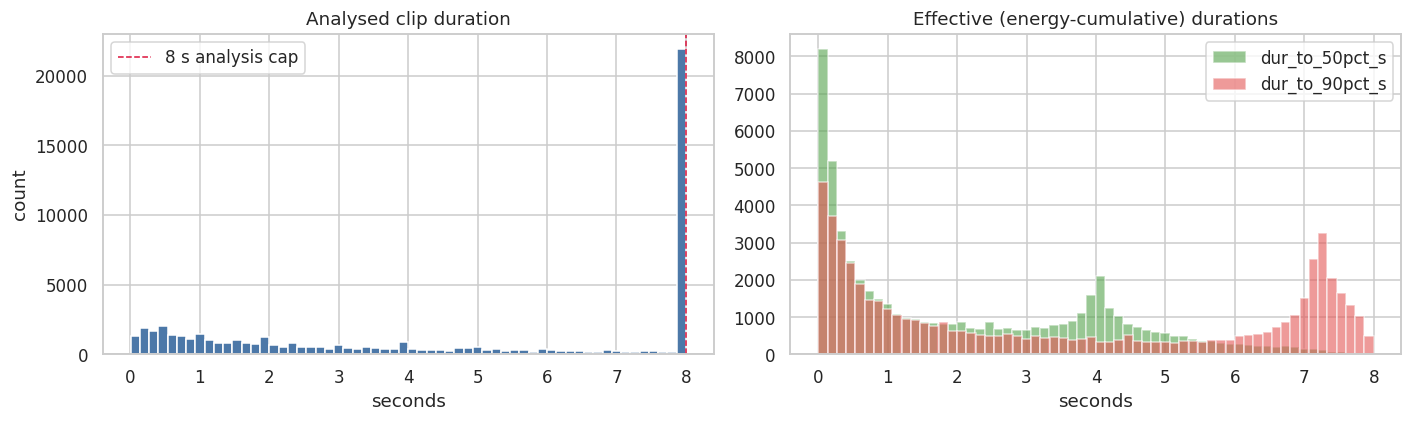

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["dur_total_s"], bins=60, color="#4c78a8")
axes[0].set(title="Analysed clip duration", xlabel="seconds", ylabel="count")
axes[0].axvline(8.0, color="crimson", ls="--", lw=1, label="8 s analysis cap")
axes[0].legend()

# effective (energy-based) durations vs total
for col, c in [("dur_to_50pct_s", "#54a24b"), ("dur_to_90pct_s", "#e45756")]:
    axes[1].hist(df[col], bins=60, alpha=0.6, label=col, color=c)
axes[1].set(title="Effective (energy-cumulative) durations", xlabel="seconds")
axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Feature distributions by group

One histogram per feature, faceted within each perceptual group. This is the
core "what does each feature look like" view. A few features are heavy-tailed
(durations, HFC, strongDecay), so we clip the x-axis at the 1st/99th percentile
for readability.

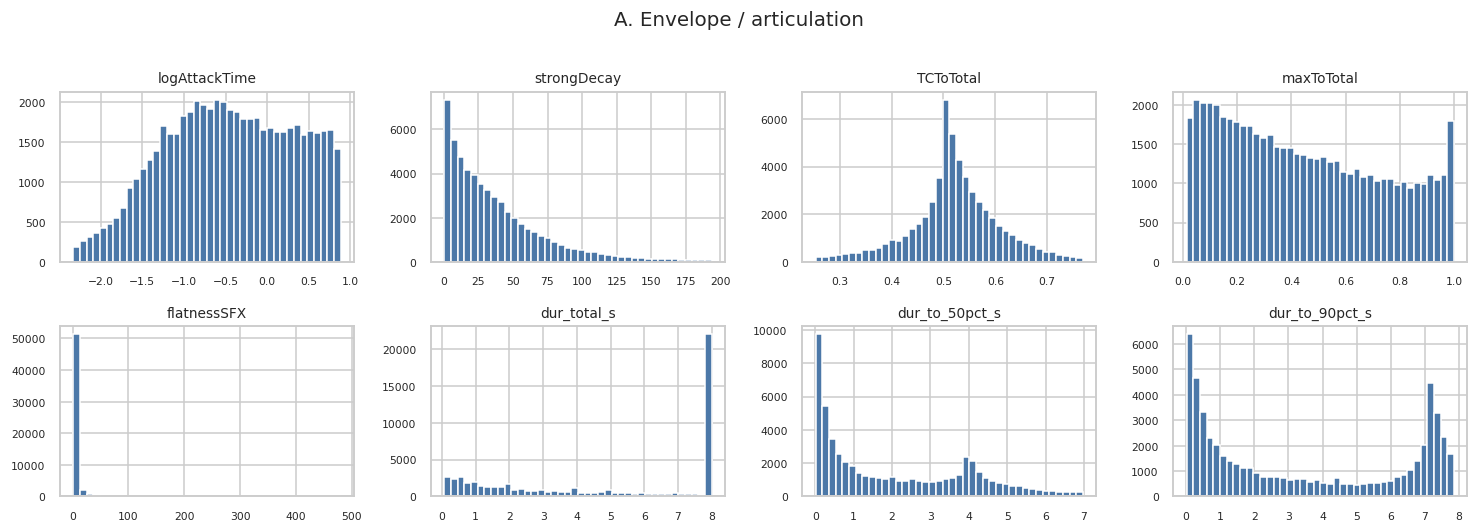

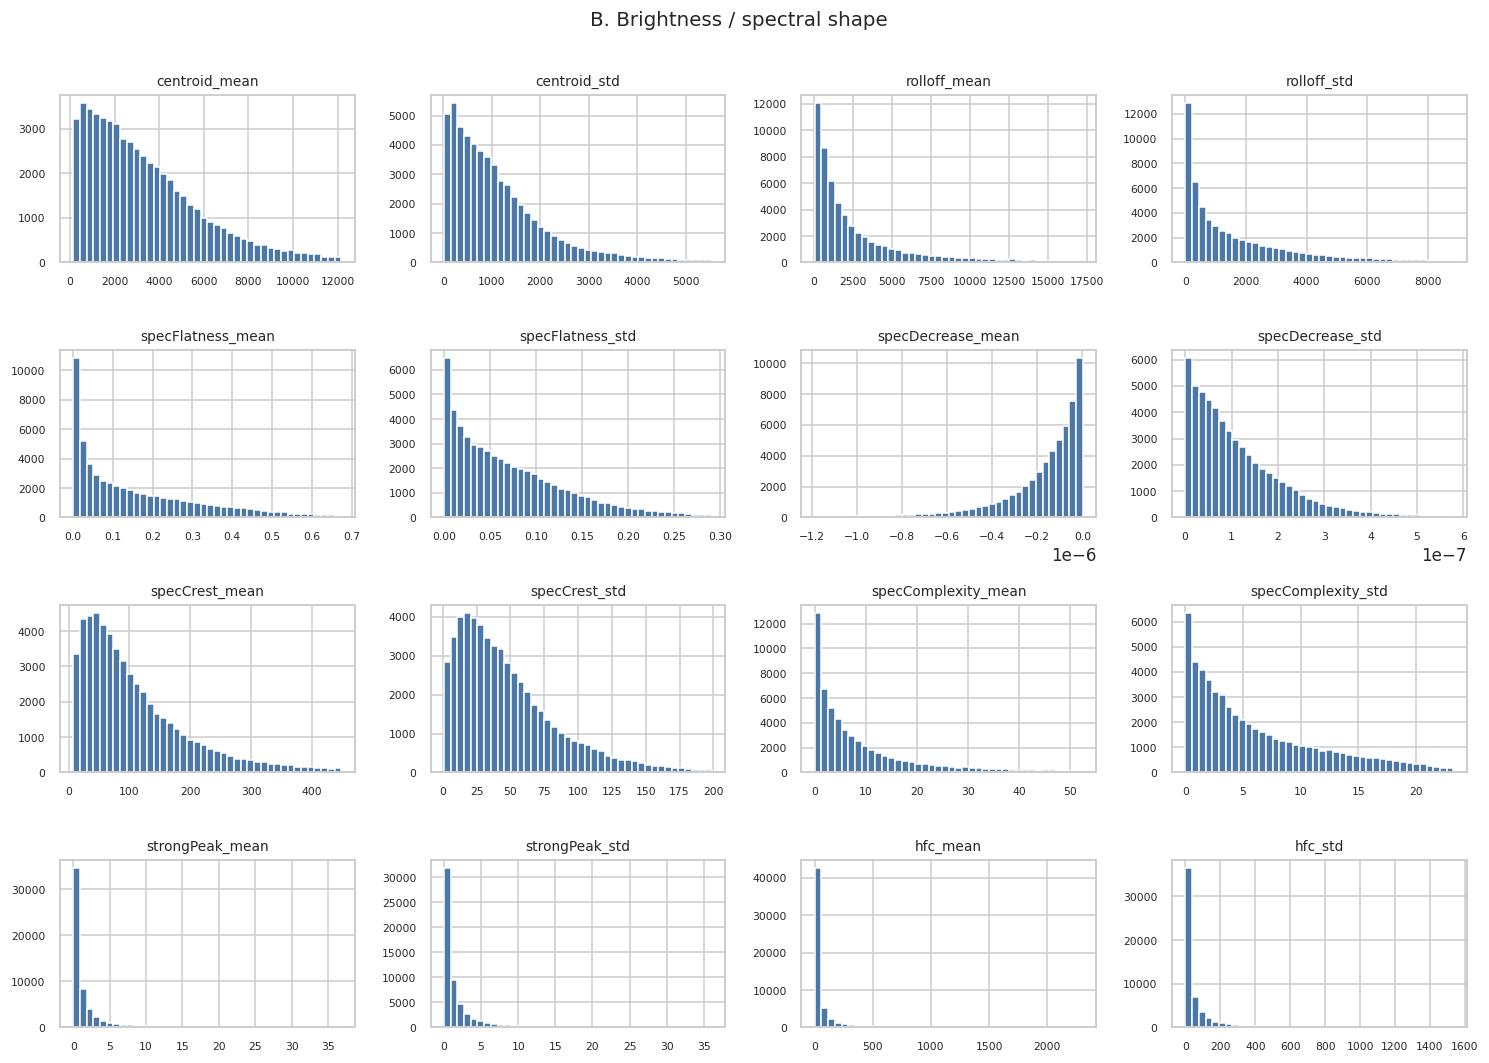

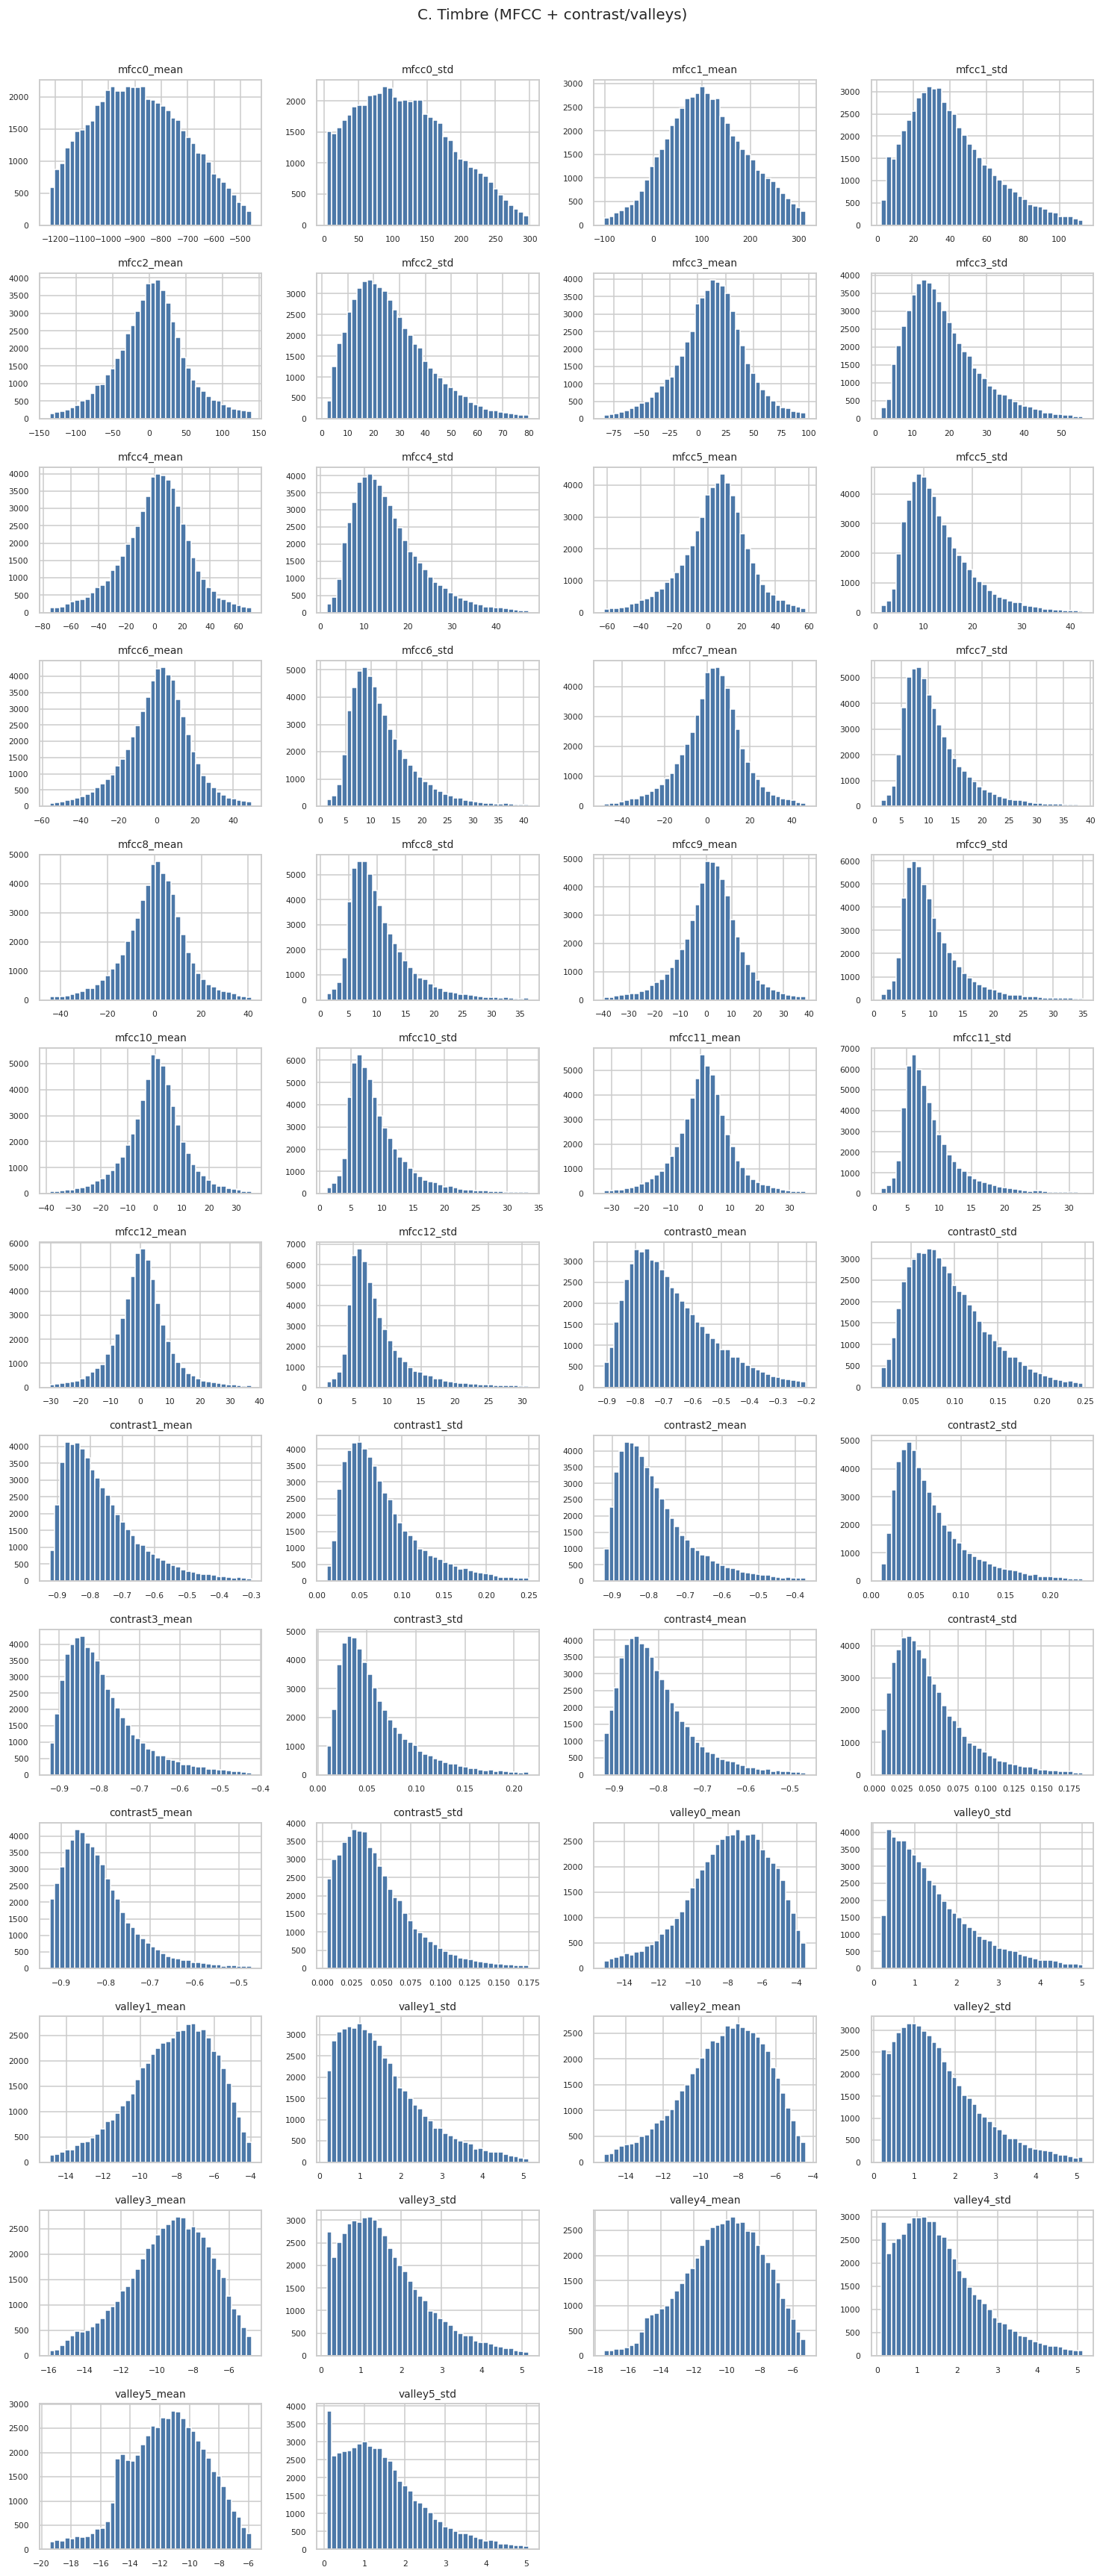

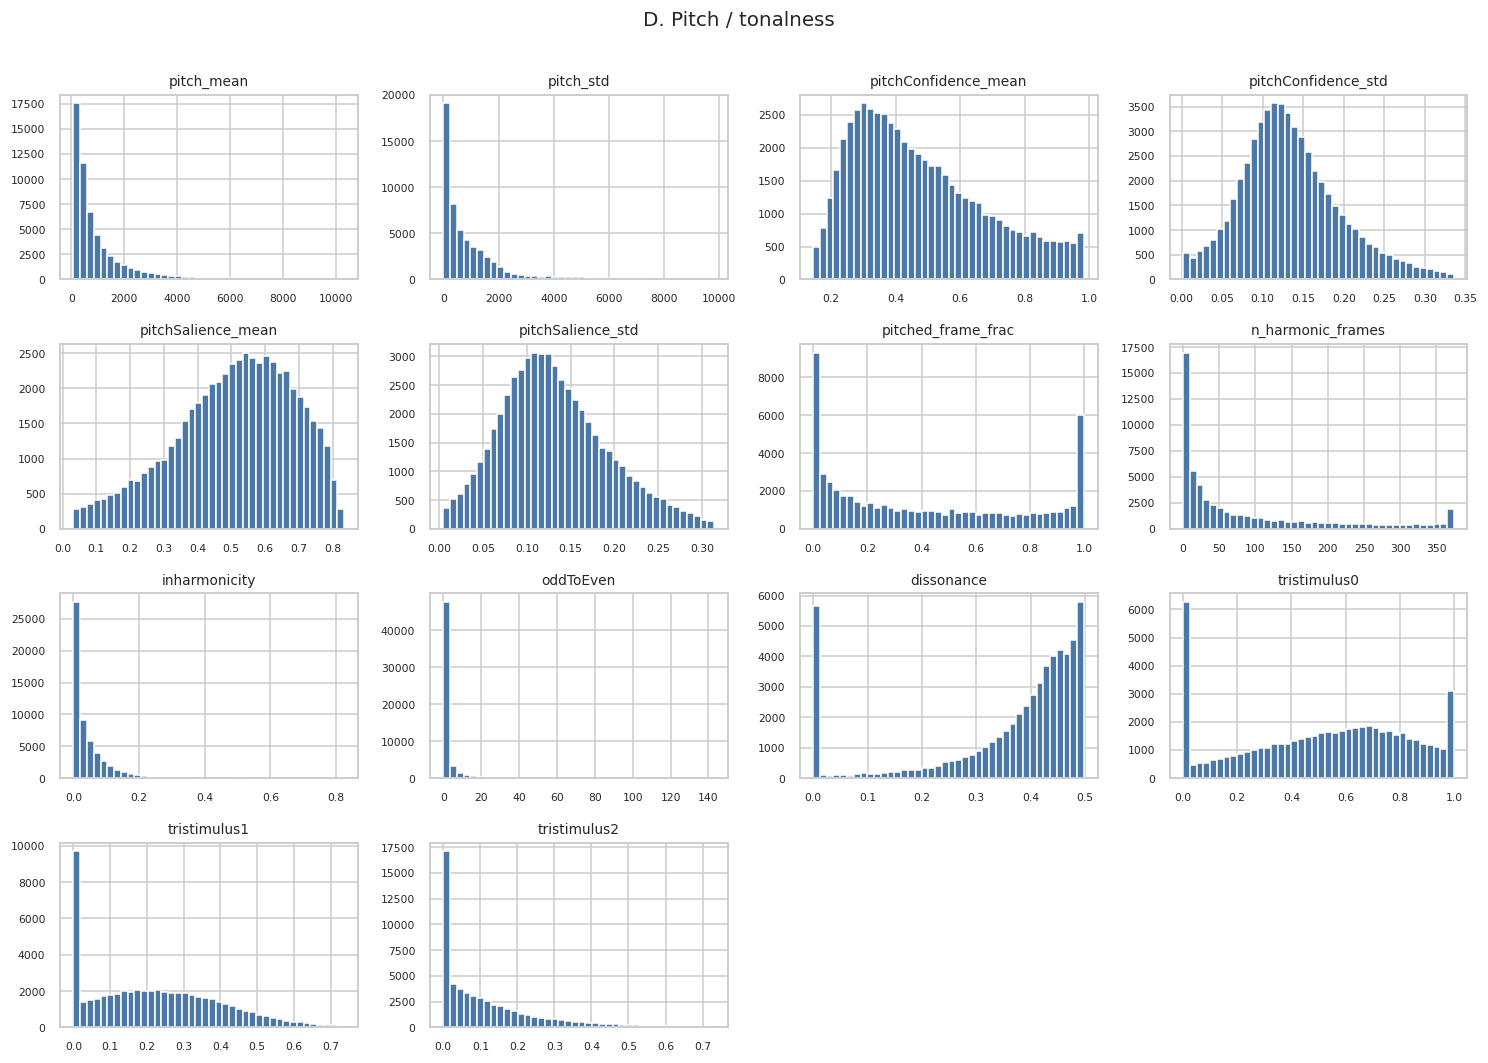

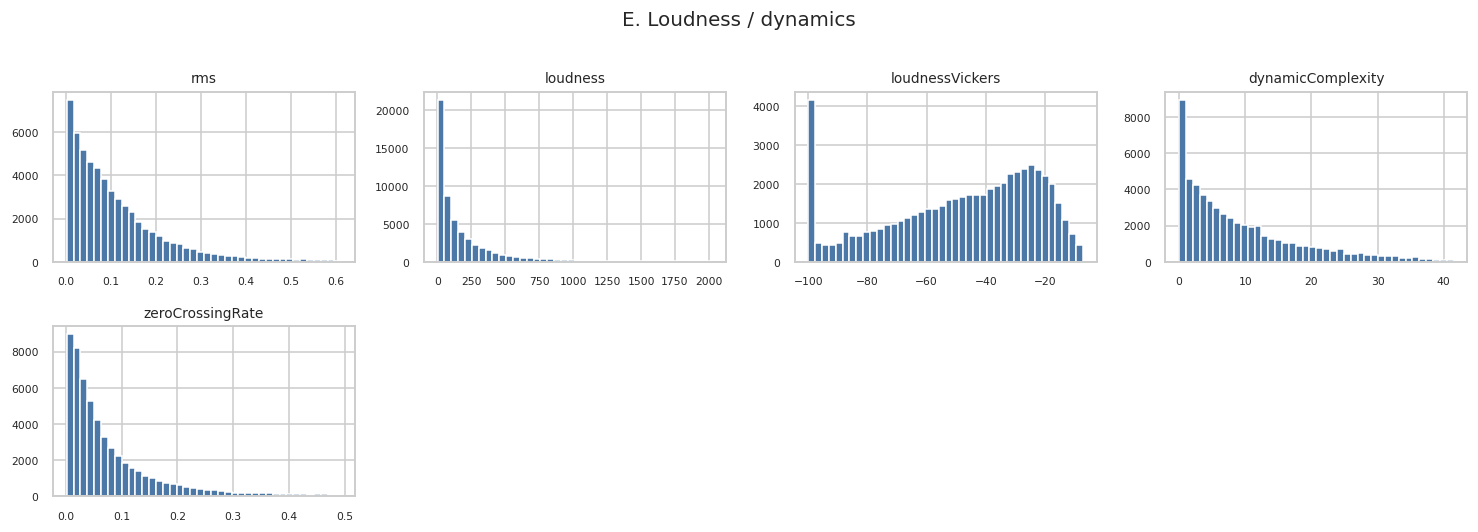

In [7]:
def plot_group(title, cols, n_cols=4):
    cols = [c for c in cols if c in df.columns]
    n_rows = int(np.ceil(len(cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 2.4 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        v = df[c].values
        lo, hi = np.percentile(v, [1, 99])
        vv = v[(v >= lo) & (v <= hi)] if hi > lo else v
        ax.hist(vv, bins=40, color="#4c78a8")
        ax.set_title(c, fontsize=9)
        ax.tick_params(labelsize=7)
    for ax in axes[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13, y=1.005)
    plt.tight_layout(); plt.show()

for g, cols in GROUPS.items():
    plot_group(g, cols)

## 5. Correlation structure

Which features move together. Helps spot redundancy (e.g. brightness measures)
and structure the latent-prediction experiments later.

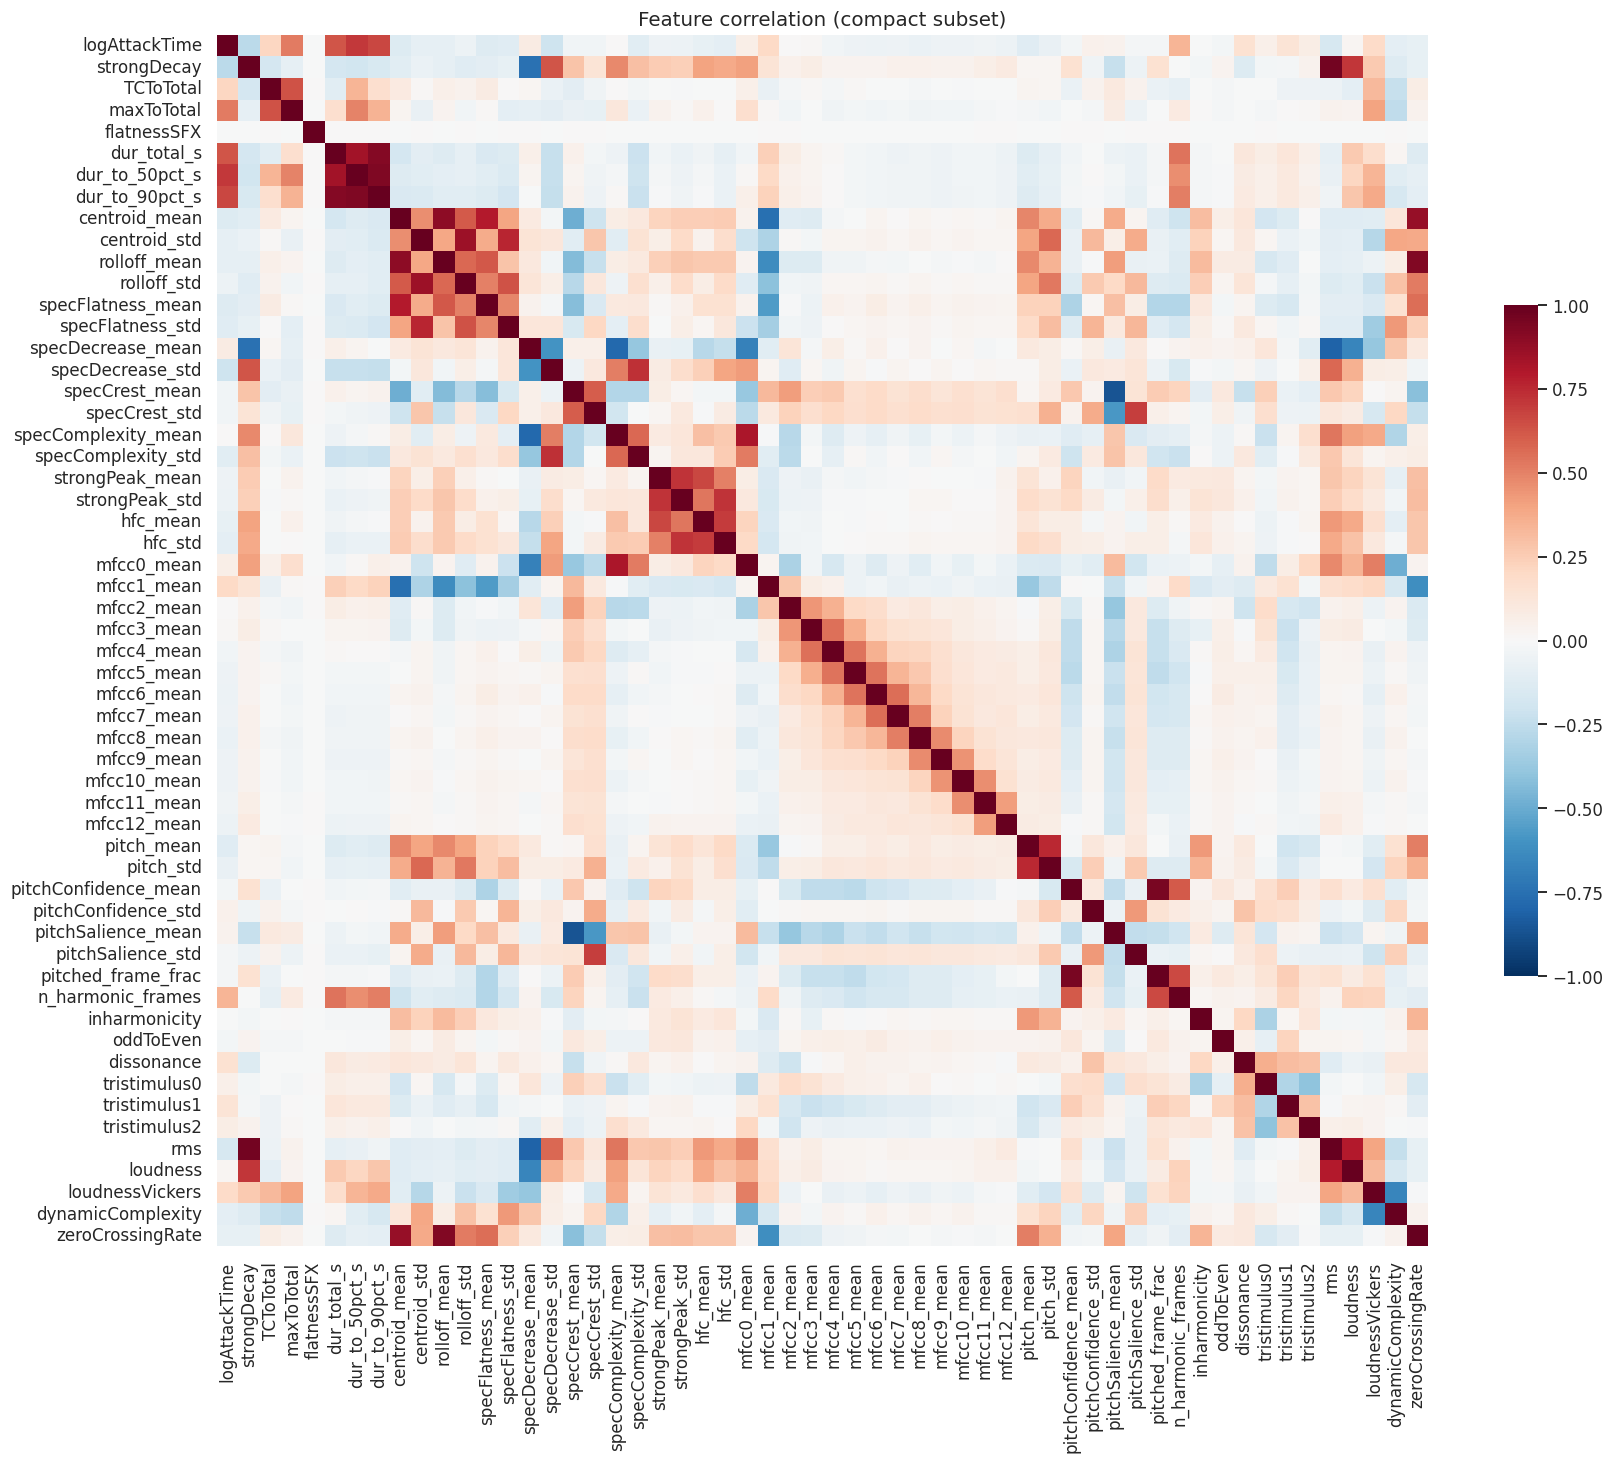

In [8]:
# Use a compact, representative subset (drop the _std twins of MFCC/contrast to
# keep the heatmap readable) — the full matrix is computed below for pair-mining.
compact = (
    GROUPS["A. Envelope / articulation"]
    + GROUPS["B. Brightness / spectral shape"]
    + [f"mfcc{i}_mean" for i in range(13)]
    + GROUPS["D. Pitch / tonalness"]
    + GROUPS["E. Loudness / dynamics"]
)
compact = [c for c in compact if c in df.columns]
corr = df[compact].corr()

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.5}, ax=ax)
ax.set_title("Feature correlation (compact subset)", fontsize=13)
plt.tight_layout(); plt.show()

In [9]:
# Most strongly correlated feature pairs across ALL numeric features.
full_corr = df[feature_cols].corr().abs()
mask = np.triu(np.ones(full_corr.shape, bool), k=1)
pairs = (full_corr.where(mask).stack().sort_values(ascending=False))
print("Top 20 most-correlated feature pairs (|r|):")
print(pairs.head(20).round(3).to_string())

Top 20 most-correlated feature pairs (|r|):
valley1_std           valley2_std           0.968
valley2_std           valley3_std           0.966
rms                   strongDecay           0.962
valley3_std           valley4_std           0.955
pitchConfidence_mean  pitched_frame_frac    0.952
valley0_std           valley1_std           0.941
valley2_mean          valley3_mean          0.934
dur_to_50pct_s        dur_to_90pct_s        0.930
rolloff_mean          zeroCrossingRate      0.928
valley1_mean          valley2_mean          0.927
valley1_std           valley3_std           0.925
valley3_mean          valley4_mean          0.924
valley4_std           valley5_std           0.923
dur_to_90pct_s        dur_total_s           0.920
mfcc0_mean            valley3_mean          0.905
valley2_std           valley4_std           0.904
valley0_std           valley2_std           0.897
centroid_mean         rolloff_mean          0.891
valley4_mean          valley5_mean          0.887
mfcc0_

## 6. Pairwise relationships across perceptual axes

Scatter of a few high-level axes (brightness, noisiness, tonalness, duration,
loudness). Sampled to 6k points for a responsive plot.

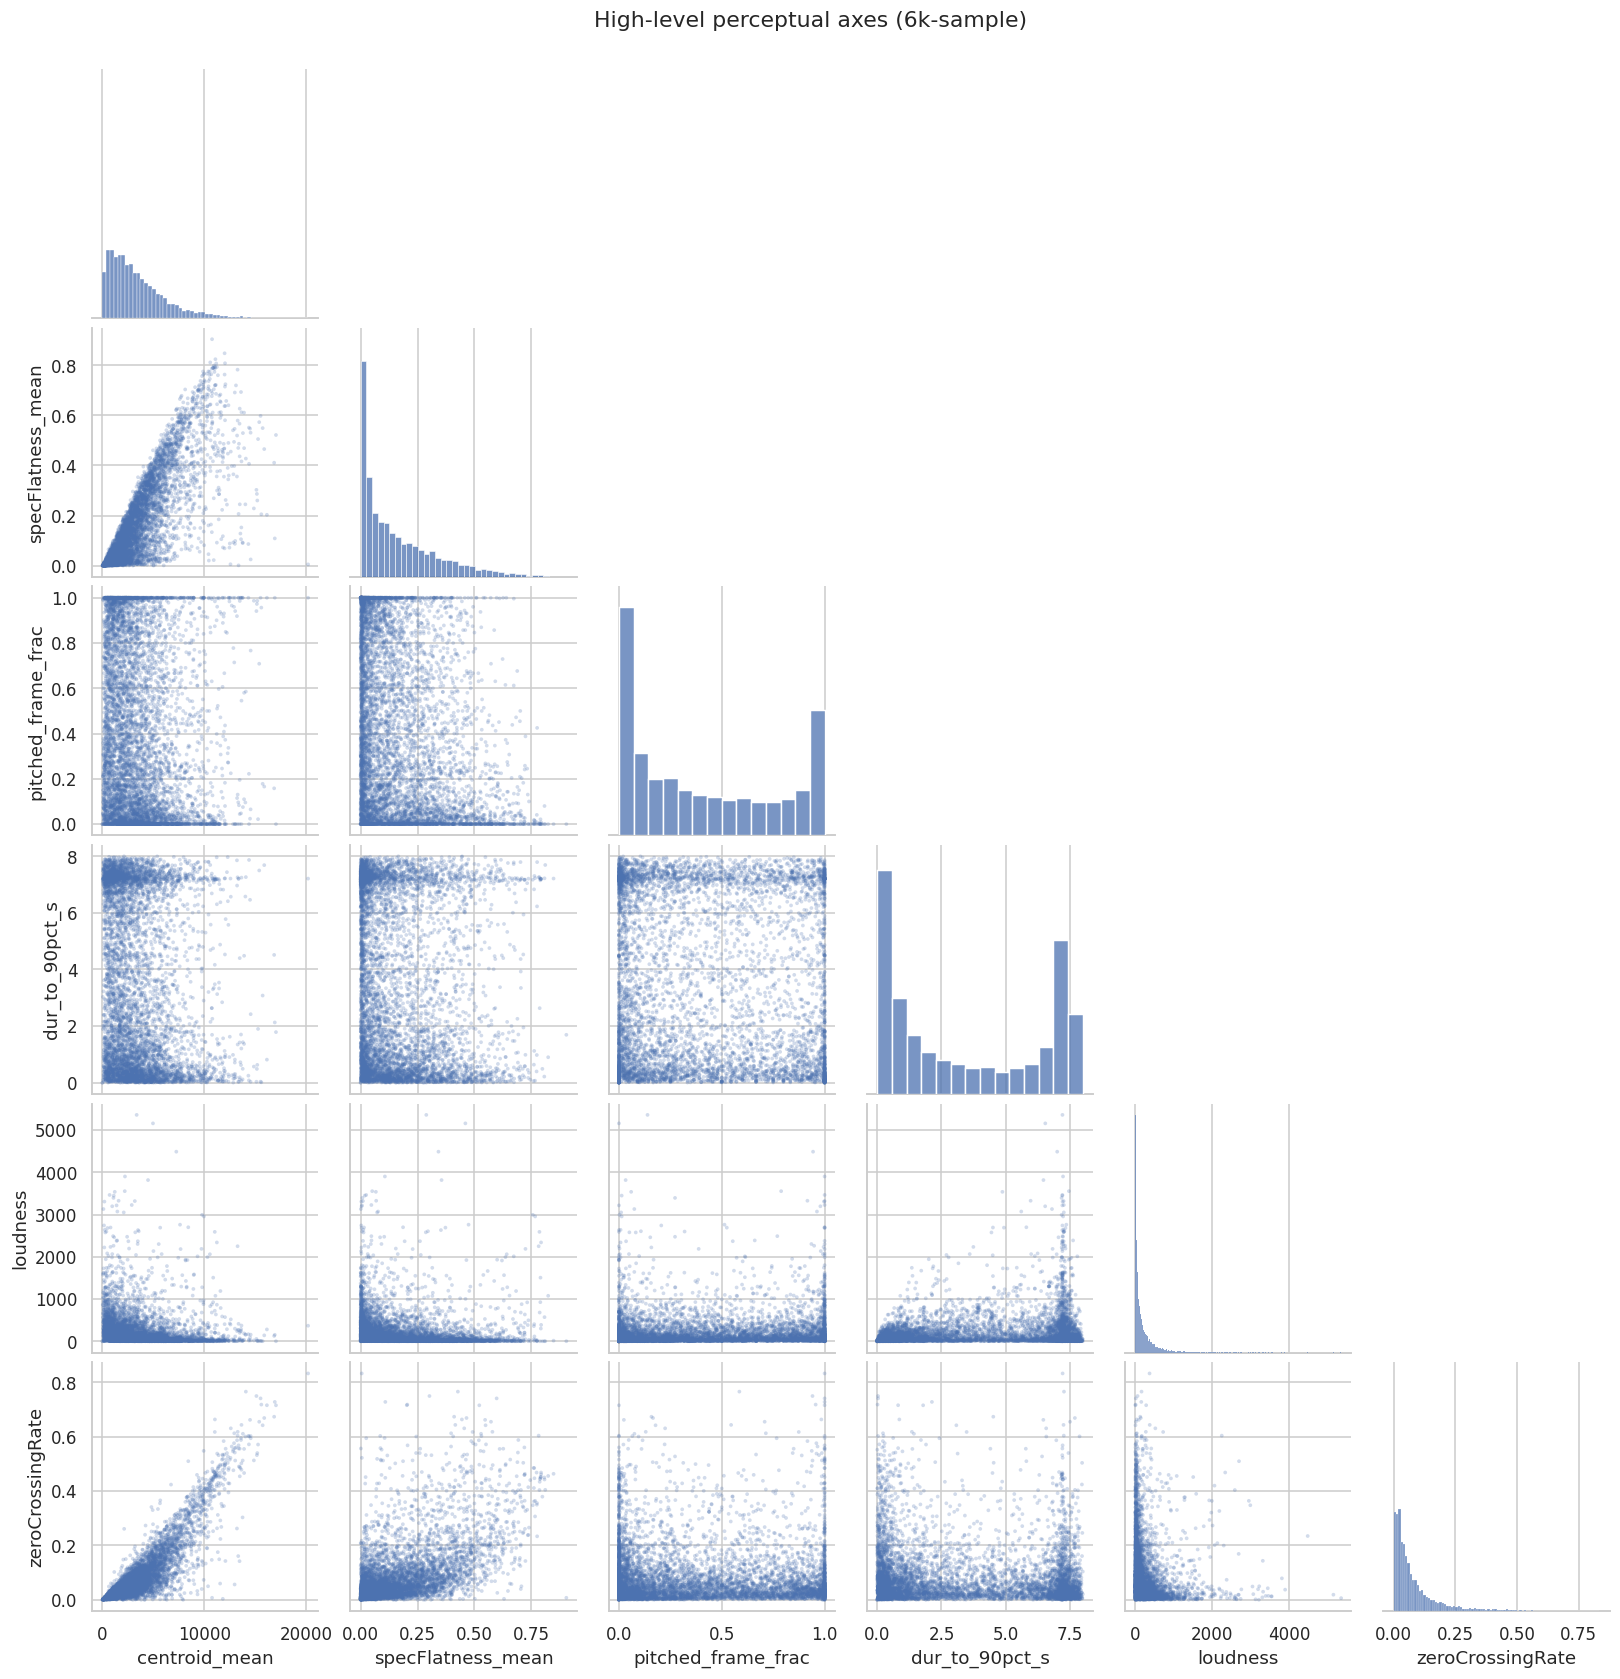

In [10]:
axes_cols = ["centroid_mean", "specFlatness_mean", "pitched_frame_frac",
             "dur_to_90pct_s", "loudness", "zeroCrossingRate"]
sample = df.sample(min(6000, len(df)), random_state=0)
g = sns.pairplot(sample[axes_cols], plot_kws=dict(s=6, alpha=0.25, edgecolor="none"),
                 diag_kind="hist", corner=True)
g.fig.suptitle("High-level perceptual axes (6k-sample)", y=1.02)
plt.show()

## 7. PCA of the feature space

How much of the variance is captured by a few components, and how features load
onto the first two PCs.

**Scaling choice:** a few features are extremely heavy-tailed — most notably
`flatnessSFX`, whose envelope-flatness ratio blows up (max ~4e8 vs median ~2) on
near-silent / degenerate clips. Plain z-scoring lets those outliers dominate the
covariance, so we use a **RobustScaler** (median / IQR) followed by clipping to
±20 before PCA. We fit a full-rank PCA so the ">=90% variance" count is correct.

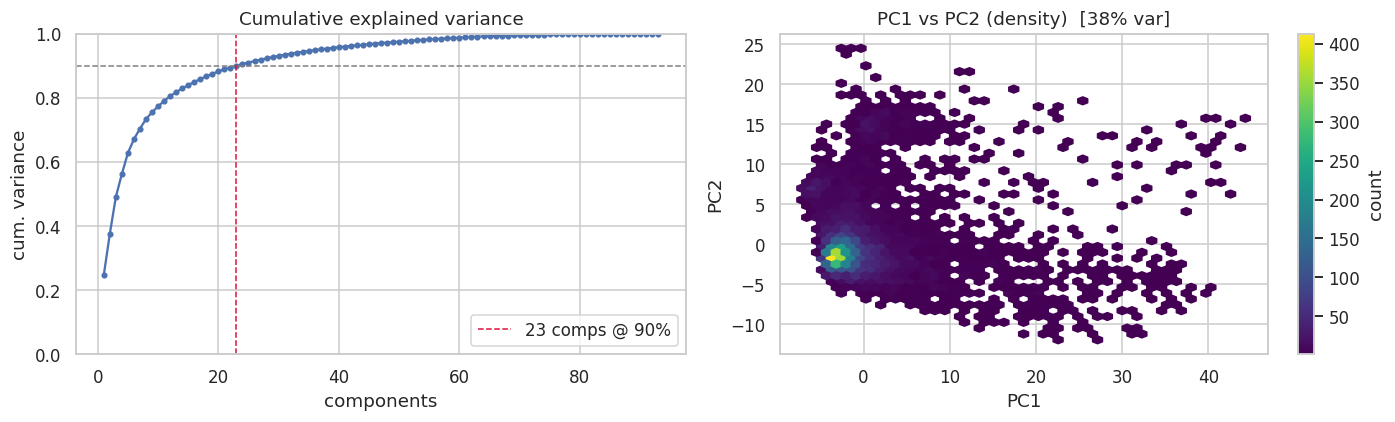

23 of 93 components explain >=90% of variance (PC1=24.9%, PC1+PC2=37.7%)


In [11]:
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

# Robust standardisation + clip tames the flatnessSFX-style outliers.
X = np.clip(RobustScaler().fit_transform(df[feature_cols].values), -20, 20)
pca = PCA(random_state=0).fit(X)          # full-rank -> correct cumulative curve
scores = pca.transform(X)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()
n90 = int(np.argmax(cum >= 0.9) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, len(cum) + 1), cum, "o-", ms=3)
axes[0].set(title="Cumulative explained variance", xlabel="components",
            ylabel="cum. variance", ylim=(0, 1))
axes[0].axhline(0.9, color="grey", ls="--", lw=1)
axes[0].axvline(n90, color="crimson", ls="--", lw=1, label=f"{n90} comps @ 90%")
axes[0].legend(); axes[0].grid(True)

samp = np.random.default_rng(0).choice(len(scores), size=min(8000, len(scores)),
                                       replace=False)
hb = axes[1].hexbin(scores[samp, 0], scores[samp, 1], gridsize=45, cmap="viridis",
                    mincnt=1)
axes[1].set(title=f"PC1 vs PC2 (density)  [{evr[:2].sum():.0%} var]",
            xlabel="PC1", ylabel="PC2")
fig.colorbar(hb, ax=axes[1], label="count")
plt.tight_layout(); plt.show()

print(f"{n90} of {len(feature_cols)} components explain >=90% of variance "
      f"(PC1={evr[0]:.1%}, PC1+PC2={evr[:2].sum():.1%})")

In [12]:
# Which features drive PC1 / PC2.
load = pd.DataFrame(pca.components_[:2].T, index=feature_cols, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    print(f"\nTop loadings on {pc}:")
    print(load[pc].abs().sort_values(ascending=False).head(8).round(3).to_string())


Top loadings on PC1:
hfc_mean           0.543
hfc_std            0.445
strongPeak_mean    0.409
strongPeak_std     0.385
oddToEven          0.196
flatnessSFX        0.127
loudness           0.124
rms                0.095

Top loadings on PC2:
oddToEven              0.797
flatnessSFX            0.413
hfc_mean               0.169
specDecrease_mean      0.100
specComplexity_mean    0.088
valley1_mean           0.076
valley2_mean           0.075
loudness               0.073


## 8. Tonalness landscape

`sfx1` mixes pitched and unpitched material. This splits the set by whether any
frame was confidently pitched and contrasts a couple of descriptors, to sanity
check the pitched/unpitched population.

clips with >=1 pitched frame: 90.7%


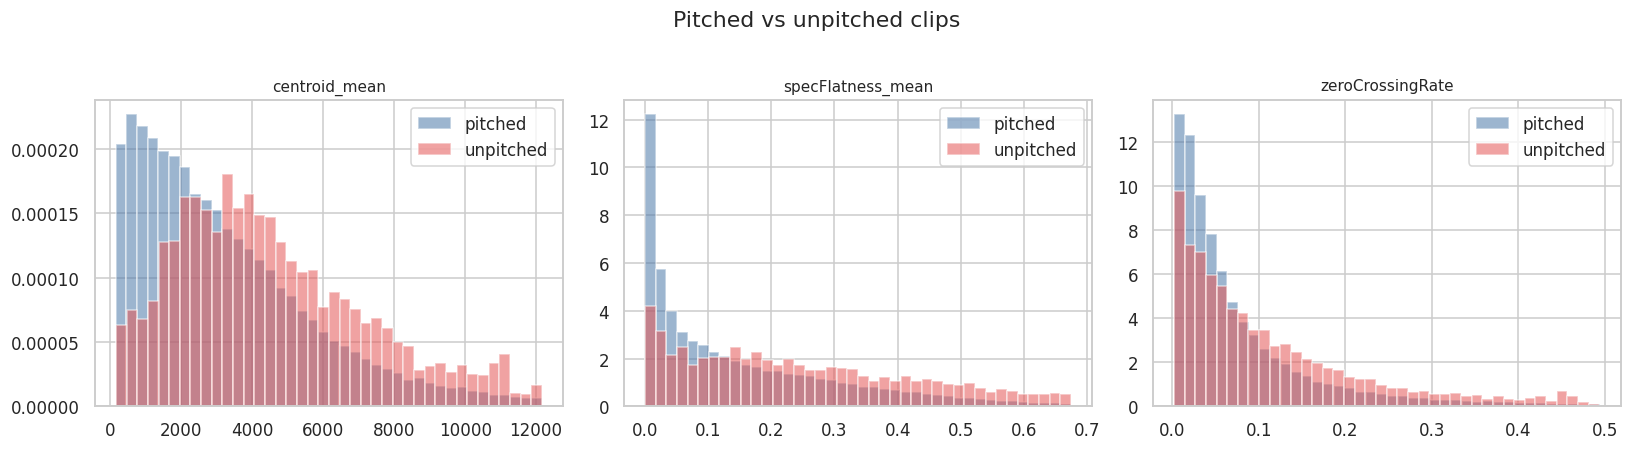

In [13]:
is_pitched = df["pitched_frame_frac"] > 0
print(f"clips with >=1 pitched frame: {is_pitched.mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["centroid_mean", "specFlatness_mean", "zeroCrossingRate"]):
    for label, m, c in [("pitched", is_pitched, "#4c78a8"),
                        ("unpitched", ~is_pitched, "#e45756")]:
        v = df.loc[m, col]
        lo, hi = np.percentile(df[col], [1, 99])
        ax.hist(v[(v >= lo) & (v <= hi)], bins=40, alpha=0.55, density=True,
                label=label, color=c)
    ax.set_title(col, fontsize=10); ax.legend()
fig.suptitle("Pitched vs unpitched clips", y=1.02)
plt.tight_layout(); plt.show()

## Summary

- **57,288 clips**, 93 numeric essentia features, no missing/constant columns.
- Harmonic descriptors are 0 (= not applicable) for the ~9–18% of clips with no
  confidently pitched frame — expected for a general SFX set (~91% have at least
  one pitched frame).
- Durations run up to the 8 s analysis cap (**~38%** of clips are capped) and the
  median effective length (`dur_to_90pct_s`) is ~2.7 s; SFX are much longer than
  the earlier percussive one-shots, so a short fixed window truncates most clips.
- A few features are extremely heavy-tailed — `flatnessSFX` especially — driven
  by near-silent/degenerate clips; robust scaling is used before PCA. Worth a
  guard (clip/winsorize) before feeding these features to a downstream model.
- Strong correlation clusters exist (brightness measures; MFCC0/loudness), but
  effective dimensionality is still moderate: ~23 robust-PCA components are
  needed for 90% of the variance, so the space is not low-rank.
- The set is a genuine pitched/unpitched mixture, a good testbed for probing
  which perceptual axes are decodable from the VAE latent.